# Customer Churn Analysis (Telecom)
**Goal:** find out which customers leave, why they are likely leaving, and where retention effort should go.

**Data:** IBM Telco Customer Churn dataset (public) - 7,043 customers, 21 columns.
**Tools:** Python (Pandas, Matplotlib, Seaborn), SQL (see `churn_queries.sql`), Power BI (see README).

In [1]:
import pandas as pd, numpy as np, sqlite3
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi']=110
df = pd.read_csv('Telco-Customer-Churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data quality checks

In [2]:
print('Missing values   :', df.isna().sum().sum())
print('Duplicate rows   :', df.duplicated().sum())
print('Duplicate IDs    :', df.customerID.duplicated().sum())
print('TotalCharges dtype:', df.TotalCharges.dtype, '(should be numeric)')
blank = df[df.TotalCharges.str.strip()=='']
print('Blank TotalCharges:', len(blank), '-> all have tenure =', blank.tenure.unique())

Missing values   : 0
Duplicate rows   : 0
Duplicate IDs    : 0
TotalCharges dtype: str (should be numeric)
Blank TotalCharges: 11 -> all have tenure = [0]


**Finding:** `TotalCharges` is stored as text because 11 rows are blank. All 11 are brand-new customers with `tenure = 0`, so they have not been billed yet. I convert the column to numeric and set these to 0.

In [3]:
df['TotalCharges'] = pd.to_numeric(df.TotalCharges.str.strip(), errors='coerce').fillna(0)
df['SeniorCitizen'] = df.SeniorCitizen.map({0:'No', 1:'Yes'})
df['churn_flag'] = (df.Churn=='Yes').astype(int)
df['tenure_group'] = pd.cut(df.tenure, [-1,12,24,48,72], labels=['0-12 months','13-24 months','25-48 months','49-72 months'])
df['charges_band'] = pd.cut(df.MonthlyCharges, [0,35,70,200], labels=['Low (<$35)','Medium ($35-70)','High (>$70)'])
df.to_csv('churn_clean.csv', index=False)   # used for SQL and Power BI
df[['TotalCharges','churn_flag','tenure_group','charges_band']].info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   TotalCharges  7043 non-null   float64 
 1   churn_flag    7043 non-null   int64   
 2   tenure_group  7043 non-null   category
 3   charges_band  7043 non-null   category
dtypes: category(2), float64(1), int64(1)
memory usage: 124.1 KB


## 2. Overall churn

In [4]:
rate = df.churn_flag.mean()
lost = df.loc[df.churn_flag==1,'MonthlyCharges'].sum()
print(f"Customers: {len(df):,} | Churned: {df.churn_flag.sum():,} | Churn rate: {rate:.1%}")
print(f"Monthly revenue lost to churn: ${lost:,.0f} ({lost/df.MonthlyCharges.sum():.1%} of total monthly revenue)")

Customers: 7,043 | Churned: 1,869 | Churn rate: 26.5%
Monthly revenue lost to churn: $139,131 (30.5% of total monthly revenue)


## 3. Churn drivers

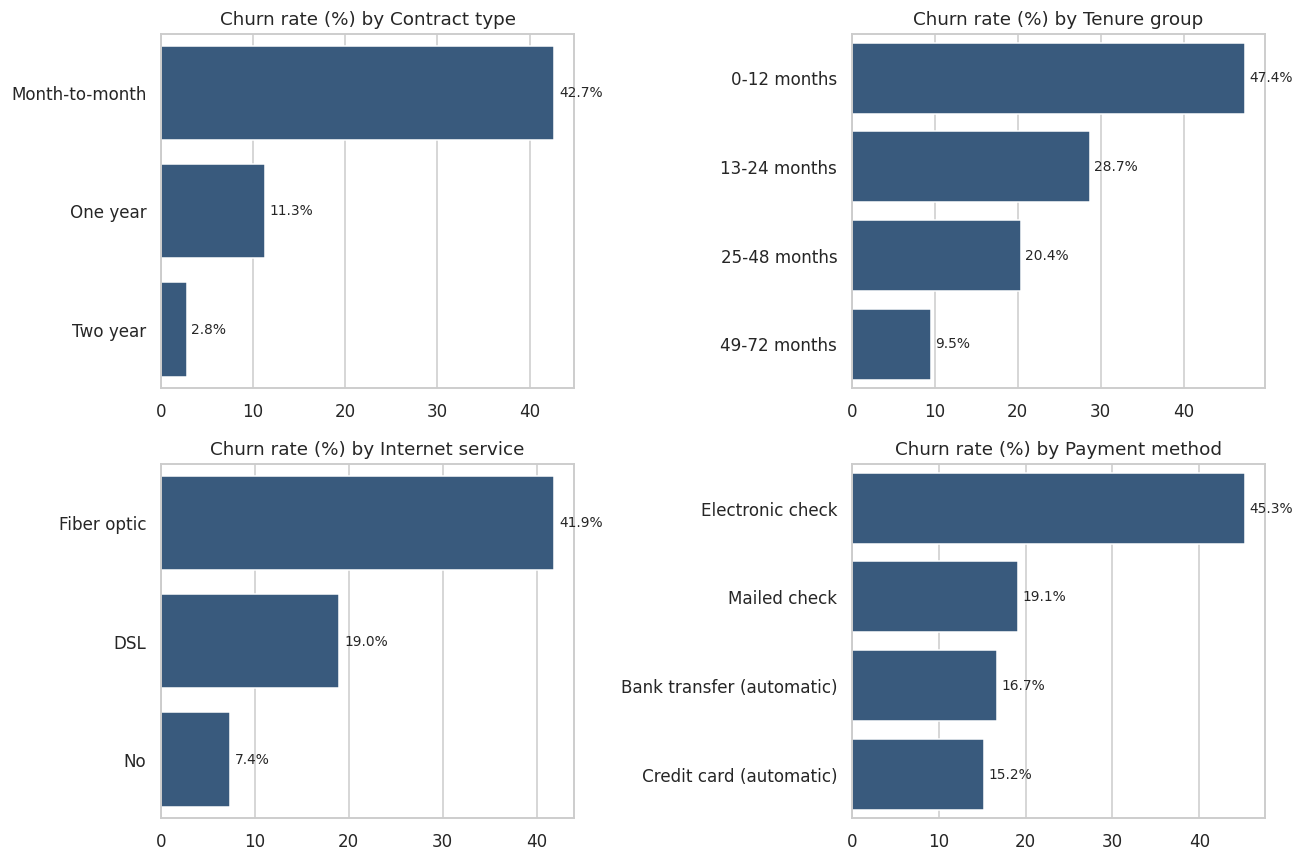

In [5]:
def rate_by(col):
    return df.groupby(col, observed=True).churn_flag.mean().mul(100).round(1)

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, col, title in zip(ax.ravel(), ['Contract','tenure_group','InternetService','PaymentMethod'],
        ['Contract type','Tenure group','Internet service','Payment method']):
    r = rate_by(col).sort_values(ascending=False) if col!='tenure_group' else rate_by(col)
    sns.barplot(x=r.values, y=r.index.astype(str), ax=a, color='#2E5A88')
    a.set_title(f'Churn rate (%) by {title}'); a.set_xlabel(''); a.set_ylabel('')
    for i,v in enumerate(r.values): a.text(v+0.5, i, f'{v}%', va='center', fontsize=9)
plt.tight_layout(); plt.show()

**What the charts say:**
- **Contract type is the strongest driver.** Month-to-month customers churn at 42.7% vs 11.3% (one-year) and 2.8% (two-year).
- **Early tenure is risky.** 47.4% of customers in their first year leave, vs 9.5% after four years.
- **Fiber optic customers churn at 41.9%**, more than double DSL (19.0%).
- **Electronic check users churn at 45.3%**, almost 3x the automatic payment methods.

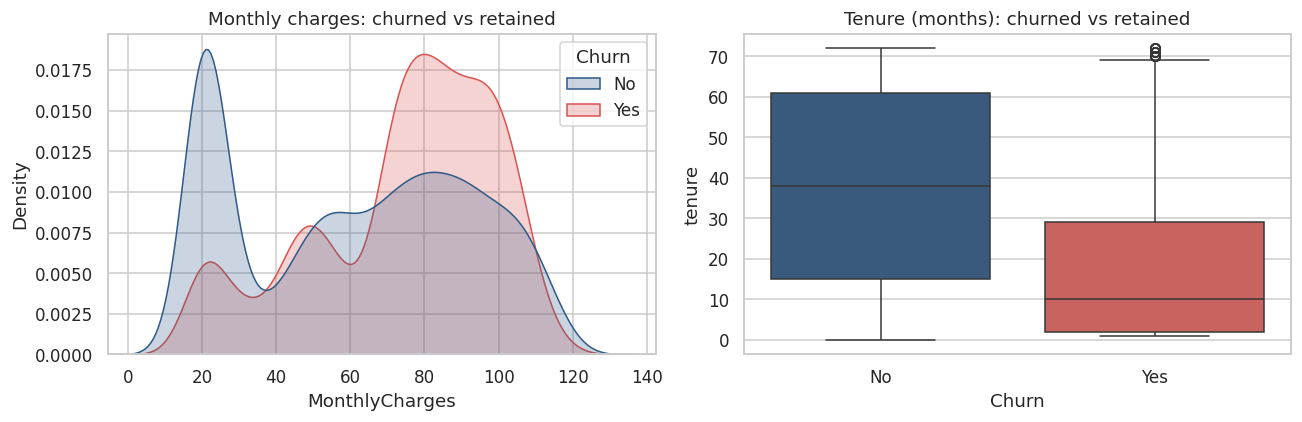

      MonthlyCharges        tenure       
                mean median   mean median
Churn                                    
No              61.3   64.4   37.6   38.0
Yes             74.4   79.6   18.0   10.0


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, ax=ax[0], palette=['#2E5A88','#D9534F'])
ax[0].set_title('Monthly charges: churned vs retained')
sns.boxplot(data=df, x='Churn', y='tenure', ax=ax[1], palette=['#2E5A88','#D9534F'], hue='Churn', legend=False)
ax[1].set_title('Tenure (months): churned vs retained')
plt.tight_layout(); plt.show()
print(df.groupby('Churn')[['MonthlyCharges','tenure']].agg(['mean','median']).round(1))

Churned customers pay more per month (avg $74.44 vs $61.27) and leave early (median tenure 10 months vs 38).

## 4. Do support add-ons help?

In [7]:
net = df[df.InternetService!='No']
tbl = net.groupby(['TechSupport','OnlineSecurity']).churn_flag.agg(['size','mean'])
tbl['mean'] = (tbl['mean']*100).round(1); tbl.columns=['customers','churn_rate_%']
tbl.sort_values('churn_rate_%', ascending=False)

,,customers,churn_rate_%
TechSupport,OnlineSecurity,,
No,No,2553,49.0
Yes,No,945,22.3
No,Yes,920,21.3
Yes,Yes,1099,9.0


Internet customers with **neither** Tech Support nor Online Security churn at 49.0%. With **both**, only 9.0%.

## 5. High-risk segment

In [8]:
seg = df[(df.Contract=='Month-to-month') & (df.InternetService=='Fiber optic') & (df.tenure<=12)]
print(f"Customers: {len(seg):,} ({len(seg)/len(df):.1%} of base)")
print(f"Churn rate: {seg.churn_flag.mean():.1%}")
print(f"Monthly revenue: ${seg.MonthlyCharges.sum():,.0f}")
share = seg.churn_flag.sum()/df.churn_flag.sum()
print(f"Share of ALL churned customers: {share:.1%}")

Customers: 916 (13.0% of base)
Churn rate: 70.2%
Monthly revenue: $75,183
Share of ALL churned customers: 34.4%


## 6. SQL analysis

In [9]:
con = sqlite3.connect(':memory:'); df.to_sql('churn', con, index=False)
sql = open('churn_queries.sql').read()
for q in [s.strip() for s in sql.split(';') if 'SELECT' in s]:
    print(q.splitlines()[0] if q.startswith('--') else '')
    display(pd.read_sql(q, con))

-- Customer Churn Analysis (Telecom) - SQL queries


,customers,churned,churn_rate_pct,monthly_revenue_lost,pct_of_monthly_revenue
0,7043,1869,26.5,139131.0,30.5


-- Q2. Churn by contract type


,Contract,customers,churn_rate_pct
0,Month-to-month,3875,42.7
1,One year,1473,11.3
2,Two year,1695,2.8


-- Q3. Churn by tenure group


...

,charges_band,Contract,churn_rate_pct,risk_rank
0,High (>$70),Month-to-month,52.7,1
1,High (>$70),One year,17.4,2
2,High (>$70),Two year,4.8,3
3,Low (<$35),Month-to-month,24.3,1
4,Low (<$35),One year,3.1,2
5,Low (<$35),Two year,0.8,3
6,Medium ($35-70),Month-to-month,35.3,1
7,Medium ($35-70),One year,7.8,2
8,Medium ($35-70),Two year,2.1,3


-- Q8. Share of all churn contributed by each contract type (window function)


,Contract,churned,share_of_all_churn_pct
0,Month-to-month,1655,88.6
1,One year,166,8.9
2,Two year,48,2.6


-- Q9. How many times riskier is each contract type than the average customer? (CTE + JOIN)


,Contract,customers,churn_rate_pct,risk_multiple_vs_avg
0,Month-to-month,3875,42.7,1.61
1,One year,1473,11.3,0.42
2,Two year,1695,2.8,0.11


## 7. Key findings and recommendations
1. **26.5% of customers churned**, taking **$139K of monthly revenue (30.5%)** with them.
2. **Month-to-month contracts account for 88.6% of all churn.** Offer discounts or perks for moving to 1- or 2-year plans.
3. **High-risk segment:** month-to-month + fiber optic + first-year customers churn at **70.2%** (916 customers, $75K monthly revenue). Target them with onboarding calls and early-life offers.
4. **Bundle Tech Support and Online Security** for internet customers - churn drops from 49.0% to 9.0% for customers who have both.
5. **Move electronic-check customers to auto-pay** (45.3% vs ~16% churn) with a small incentive.

*Caveat: this is observational data. These factors are associated with churn, not proven causes.*